In [ ]:
#Data Collection Part 1
import asyncio
from playwright.async_api import async_playwright
import csv
import random
import os

async def block_aggressively(route):
    try:
        if route.request.resource_type in ["image", "stylesheet", "font", "media"]:
            await route.abort()
        else:
            await route.continue_()
    except Exception:
        pass

def init_csv(filename):
    file_exists = os.path.isfile(filename)
    if not file_exists:
        with open(filename, 'a', newline='', encoding='utf-8') as f:
            writer = csv.writer(f)
            writer.writerow(['Region', 'Brand', 'Title', 'Price', 'URL'])

async def strictly_sequential_scrape():
    regions = ['ulytauskaya-oblast']
    brand = 'toyota'
    max_pages = 73
    filename = 'final_toyota_sequential.csv'
    
    init_csv(filename)
    total_collected = 0

    async with async_playwright() as p:
        browser = await p.chromium.launch(headless=True)
        context = await browser.new_context(
            user_agent="Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
        )
        
        print(f"Starting strictly sequential scrape for {len(regions)} regions...")
        
        for region in regions:
            print(f"\n--- Switching to region: {region.upper()} ---")
            
            page = await context.new_page()
            await page.route("**/*", block_aggressively)
            
            for page_num in range(1, max_pages + 1):
                url = f"https://kolesa.kz/cars/{brand}/{region}/" if page_num == 1 else f"https://kolesa.kz/cars/{brand}/{region}/?page={page_num}"
                
                page_results = []
                
                try:
                    print(f"[{region.upper()}] Opening page {page_num}...")
                    await page.goto(url, wait_until="domcontentloaded", timeout=60000)
                    
                    try:
                        await page.wait_for_selector('.a-list__item', timeout=5000)
                    except Exception:
                        print(f"Cars ended in {region.upper()} on page {page_num}.")
                        break
                    
                    cars = await page.query_selector_all('.a-list__item')
                    if len(cars) == 0:
                        break
                        
                    for car in cars:
                        try:
                            title_el = await car.query_selector('.a-card__title')
                            title = await title_el.inner_text() if title_el else "No title"
                            
                            price_el = await car.query_selector('.a-card__price')
                            price = await price_el.inner_text() if price_el else "Price not specified"
                            
                            link_el = await car.query_selector('.a-card__link')
                            link = "https://kolesa.kz" + await link_el.get_attribute('href') if link_el else ""
                            
                            page_results.append([region, brand, title.strip(), price.strip(), link])
                        except Exception:
                            continue
                            
                except Exception as e:
                    print(f"Error on page {page_num}: {str(e)[:50]}...")
                    await asyncio.sleep(15) 
                
                finally:
                    if page_results:
                        with open(filename, 'a', newline='', encoding='utf-8') as f:
                            writer = csv.writer(f)
                            writer.writerows(page_results)
                        total_collected += len(page_results)
                    
                    await asyncio.sleep(random.uniform(3, 5))
            
            await page.close()
            
            print(f"Changing region... resting for 10 seconds.")
            await asyncio.sleep(10)
            
        await browser.close()
        
    print(f"\nScraping completed! Total cars collected: {total_collected}.")

await strictly_sequential_scrape()

In [ ]:
#Data Collection Part 2
import asyncio
from playwright.async_api import async_playwright
from playwright_stealth import Stealth
import csv
import random
import re
import os

async def intercept_request(route):
    if route.request.resource_type in ["image", "media", "font", "stylesheet", "other"]:
        return await route.abort()
    
    url = route.request.url.lower()
    if any(tracker in url for tracker in ["yandex", "google", "mc.yandex", "analytics", "pixel"]):
        return await route.abort()
        
    return await route.continue_()

async def scrape_details():
    input_file = 'toyota_2k_part_5.csv' 
    output_file = 'combined.csv'
    
    all_urls = []
    with open(input_file, 'r', encoding='utf-8') as f:
        reader = csv.DictReader(f)
        all_urls = [row['URL'] for row in reader if 'URL' in row and row['URL']]

    start_index = 1016
    urls = all_urls[start_index:]
    
    print(f"Total {len(all_urls)} URLs in database. Continuing from index {start_index + 1}. Remaining: {len(urls)}.")

    fieldnames = [
        'URL', 'Price', 'City', 'Generation', 'Body',
        'Volume', 'Mileage', 'Transmission', 'Drive',
        'Steering', 'Color', 'Customs'
    ]

    file_exists = os.path.isfile(output_file)
    with open(output_file, 'a', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        if not file_exists:
            writer.writeheader()

    async with Stealth().use_async(async_playwright()) as p:
        browser = await p.chromium.launch(
            headless=True, 
            args=["--disable-blink-features=AutomationControlled"]
        )
        
        context_options = {
            "user_agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
            "viewport": {'width': 1920, 'height': 1080},
            "locale": 'ru-RU',
            "timezone_id": 'Asia/Almaty',
            "java_script_enabled": True
        }
        context = await browser.new_context(**context_options)
        
        for i, url in enumerate(urls, start=start_index + 1):
            print(f"[{i}/{len(all_urls)}] Parsing: {url}")
            
            page = await context.new_page()
            
            try:
                await page.route("**/*", intercept_request)
                await page.goto(url, wait_until="commit", timeout=60000)
                await page.mouse.wheel(0, random.randint(300, 800))
                await asyncio.sleep(random.uniform(0.5, 1.5))

                data = {key: '' for key in fieldnames}
                data['URL'] = url

                price_el = await page.query_selector('.offer__price')
                if price_el:
                    price_text = await price_el.inner_text()
                    data['Price'] = re.sub(r'\D', '', price_text)

                params = await page.query_selector_all('.offer__parameters dl')
                for param in params:
                    dt = await param.query_selector('dt')
                    dd = await param.query_selector('dd')
                    if dt and dd:
                        key = (await dt.inner_text()).strip()
                        val = (await dd.inner_text()).strip()
                        
                        if 'Город' in key: data['City'] = val
                        elif 'Поколение' in key: data['Generation'] = val
                        elif 'Кузов' in key: data['Body'] = val
                        elif 'Объем двигателя' in key: data['Volume'] = val
                        elif 'Пробег' in key: data['Mileage'] = val
                        elif 'Коробка передач' in key: data['Transmission'] = val
                        elif 'Привод' in key: data['Drive'] = val
                        elif 'Руль' in key: data['Steering'] = val
                        elif 'Цвет' in key: data['Color'] = val
                        elif 'Растаможен' in key: data['Customs'] = val

                with open(output_file, 'a', newline='', encoding='utf-8') as f:
                    writer = csv.DictWriter(f, fieldnames=fieldnames)
                    writer.writerow(data)
                
                await asyncio.sleep(random.uniform(4, 8))

                if i % 15 == 0:
                    wait = random.randint(15, 30)
                    print(f"Protective pause for {wait} seconds... Resetting session.")
                    await asyncio.sleep(wait)
                    
                    await context.close()
                    context = await browser.new_context(**context_options)

            except Exception as e:
                print(f"Error on {url}: {str(e)[:50]}")
                if "Timeout" in str(e):
                    print("Timeout or ban detected. Script stopped.")
                    break
            finally:
                if not page.is_closed():
                    await page.close()

        await browser.close()
    print("Detail collection completed or safely interrupted.")

await scrape_details()

In [17]:
import pandas as pd

print("Starting the exact URL matching process...")

regional_files = [
    "toyota_astana_cities.csv",
    "toyota_almaty_cities.csv",
    "toyota_vostochno-kazahstanskaya-oblast_cities.csv",
    "toyota_shymkent_cities.csv",
    "toyota_aktubynskaya_oblast_cities.csv",
    "toyota_'atyrauskaya-oblast'_cities.csv",
    "toyota_akmolynskaya_oblast_cities.csv",
    "toyota_zhambylskaya-oblast_cities.csv",
    "final_toyota_sequential.csv"
]

model_list = [
    "4Runner", "Agya", "Allex", "Allion", "Alphard", "Altezza", "Aqua", "Aristo", "Aurion", "Auris", 
    "Avalon", "Avanza", "Avensis", "Avensis Verso", "Aygo", "bB", "Belta", "Blade", "Blizzard", 
    "Brevis", "bZ3", "bZ3X", "bZ4X", "bZ5", "C-HR", "Caldina", "Cami", "Camry", "Camry Gracia", 
    "Camry Prominent", "Carina", "Carina E", "Carina ED", "Carina II", "Cavalier", "Celica", 
    "Celsior", "Century", "Chaser", "Corolla", "Corolla Axio", "Corolla Ceres", "Corolla Cross", 
    "Corolla II", "Corolla Levin", "Corolla Rumion", "Corolla Verso", "Corona", "Corona Exiv", 
    "Corsa", "Cressida", "Cresta", "Crown", "Crown Kluger", "Crown Majesta", "Curren", "Cynos", 
    "Duet", "Echo", "Esquire", "Estima", "Estima Emina", "Estima Lucida", "FJ Cruiser", "Fortuner", 
    "Frontlander", "Fun Cargo", "Gaia", "GR86", "Grand Hiace", "Grand Highlander", "Granvia", 
    "GT 86", "Harrier", "Hiace", "HiAce Regius", "Highlander", "Hilux", "Hilux Champ", "Hilux Surf", 
    "Innova", "Ipsum", "iQ", "Isis", "Ist", "Izoa", "Kluger", "Land Cruiser Prado", "Land Cruiser", 
    "Levin", "Lite Ace", "Mark II", "Mark II Qualis", "Mark X", "Mark X Zio", "Master Ace Surf", 
    "Matrix", "Mega Cruiser", "Mirai", "Model F", "MR-S", "MR2", "Nadia", "Noah", "Opa", "Paseo", 
    "Passo", "Passo Sette", "Picnic", "Pixis Epoch", "Platz", "Porte", "Premio", "Previa", "Prius", 
    "Prius C", "Prius Prime", "Prius V", "ProAce Verso", "Probox", "Progres", "Pronard", "Ractis", 
    "Raize", "Raum", "RAV4", "Roomy", "Rumion", "Rush", "Sai", "Scepter", "Sequoia", "Sera", 
    "Sienna", "Sienta", "Soarer", "Solara", "Spacio", "Spade", "Sparky", "Sprinter", "Sprinter Carib", 
    "Sprinter Marino", "Sprinter Trueno", "Starlet", "Succeed", "Supra", "T100", "Tacoma", "Tank", 
    "Tercel", "Town Ace", "Town Ace Noah", "Tundra", "Urban Cruiser", "Vanguard", "Vellfire", 
    "Veloz", "Venza", "Verossa", "Verso", "Vios", "Vista", "Vitz", "Voltz", "Voxy", "Wigo", 
    "Wildlander", "WiLL Cypha", "Will Vi", "WiLL VS", "Windom", "Wish", "xA", "Yaris", "Yaris Cross", "Yaris Verso"
]
model_list.sort(key=len, reverse=True)

print("Compiling the mapping database...")
url_to_model = {}

for f in regional_files:
    temp_df = pd.read_csv(f)
    for _, row in temp_df.iterrows():
        url = str(row['URL'])
        title = str(row['Title']).upper()
        
        found_model = "Other Toyota"
        for m in model_list:
            if m.upper() in title:
                found_model = m
                break
        
        url_to_model[url] = found_model

print("Loading the main file combined.csv...")
df_combined = pd.read_csv("combined.csv")

def map_model(url):
    return url_to_model.get(str(url), "Other Toyota")

df_combined['Model'] = df_combined['URL'].apply(map_model)

df_combined.to_csv("combined_with_exact_models.csv", index=False)

print("\nMerging completed!")
print(f"Total rows in the file: {len(df_combined)}")
print(f"Successfully found matches: {len(df_combined[df_combined['Model'] != 'Other Toyota'])}")


Starting the exact URL matching process...
Compiling the mapping database...
Loading the main file combined.csv...

Merging completed!
Total rows in the file: 38600
Successfully found matches: 38595


In [57]:
import pandas as pd
import numpy as np
import re

df = pd.read_csv("combined_with_exact_models.csv", encoding='utf-8-sig')
df.rename(columns={'URL': 'Ссылка', 'Model': 'Модель'}, inplace=True, errors='ignore')

def extract_year(text):
    if pd.isna(text):
        return np.nan
    match = re.search(r'\b(19\d{2}|20\d{2})\b', str(text))
    return int(match.group(1)) if match else np.nan

df['Год'] = df['Поколение'].apply(extract_year)
df.drop_duplicates(subset=['Ссылка'], keep='first', inplace=True)

def clean_numeric(value):
    if pd.isna(value):
        return np.nan
    cleaned = ''.join(filter(str.isdigit, str(value)))
    return int(cleaned) if cleaned else np.nan

if 'Цена' in df.columns:
    df['Цена'] = df['Цена'].apply(clean_numeric)
if 'Пробег' in df.columns:
    df['Пробег'] = df['Пробег'].apply(clean_numeric)

df.dropna(subset=['Цена', 'Год', 'Модель'], inplace=True)

current_year = 2026
df['Возраст'] = current_year - df['Год']

df.loc[(df['Возраст'] > 1) & (df['Пробег'] <= 10), 'Пробег'] = np.nan
mask_real_km = (df['Пробег'] > 100) & (df['Возраст'] > 0)
avg_km_per_year = (df.loc[mask_real_km, 'Пробег'] / df.loc[mask_real_km, 'Возраст']).median()
if pd.isna(avg_km_per_year): avg_km_per_year = 18000

df['Пробег'] = df['Пробег'].fillna(df['Возраст'] * avg_km_per_year)
df.loc[(df['Возраст'] == 0) & (df['Пробег'].isna()), 'Пробег'] = 5

if 'Объем' in df.columns:
    df['Тип_топлива'] = df['Объем'].str.extract(r'\((.*?)\)')
    df['Объем_двигателя'] = df['Объем'].str.extract(r'([\d\.]+)').astype(float)
    df['Объем_двигателя'] = df.groupby('Модель')['Объем_двигателя'].transform(lambda x: x.fillna(x.median()))
    df['Объем_двигателя'] = df['Объем_двигателя'].fillna(df['Объем_двигателя'].median())
    df.drop(columns=['Объем'], inplace=True)

cat_cols = ['Модель', 'Город', 'Цвет', 'Кузов', 'Коробка', 'Привод', 'Руль', 'Растаможен', 'Тип_топлива']
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].fillna('Не указан').astype(str).str.strip().str.capitalize()

df['Пробег'] = df['Пробег'].round(0).astype('Int64')
df['Цена'] = df['Цена'].astype('Int64')
df['Год'] = df['Год'].astype('Int64')
df['Возраст'] = df['Возраст'].astype('Int64')

df = df[(df['Цена'] >= 500000) & (df['Цена'] <= 100000000)]
df = df[(df['Год'] >= 1970) & (df['Год'] <= 2026)]

cols_to_drop = ['Unnamed: 0', 'raw_html', 'Поколение']
df.drop(columns=[c for c in cols_to_drop if c in df.columns], inplace=True, errors='ignore')

df.to_csv("toyota_cleaned_final.csv", index=False, encoding='utf-8-sig')

--- 1. STATISTICAL SUMMARY ---
              Цена      Пробег       Год   Возраст  Объем_двигателя
count     31258.00    31258.00  31258.00  31258.00         31258.00
mean   12357113.44   208044.60   2009.03     16.97             2.70
std    11145129.85   132340.67      9.12      9.12             0.79
min      500000.00        2.00   1979.00      1.00             0.90
25%     5000000.00   102514.00   2002.00      9.00             2.40
50%     9150000.00   200000.00   2010.00     16.00             2.50
75%    15500000.00   296044.00   2017.00     24.00             3.00
max    83000000.00  1013040.00   2025.00     47.00             5.70

Missing values count:
Ссылка             0
Цена               0
Город              0
Кузов              0
Пробег             0
Коробка            0
Привод             0
Руль               0
Цвет               0
Растаможен         0
Модель             0
Год                0
Возраст            0
Тип_топлива        0
Объем_двигателя    0
dtype: int64


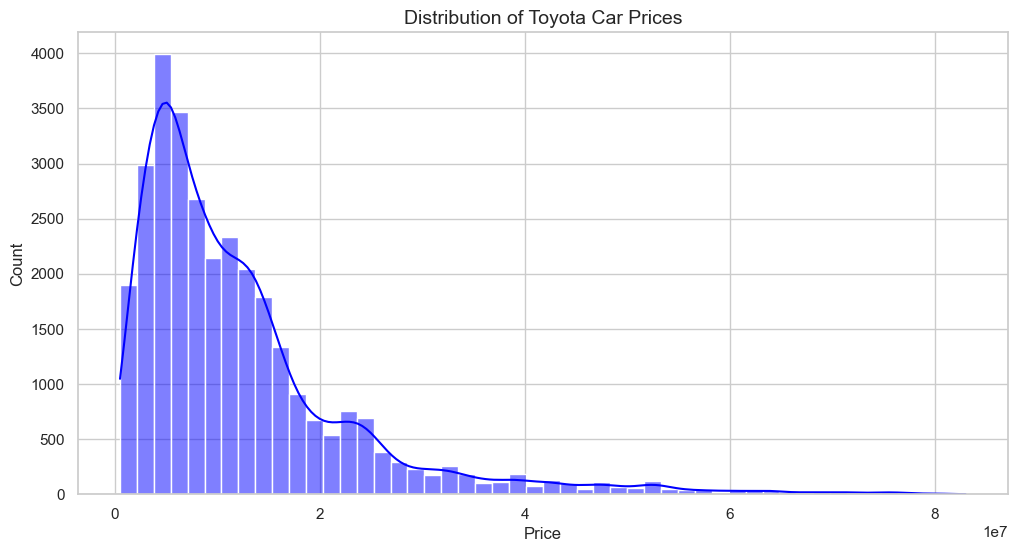

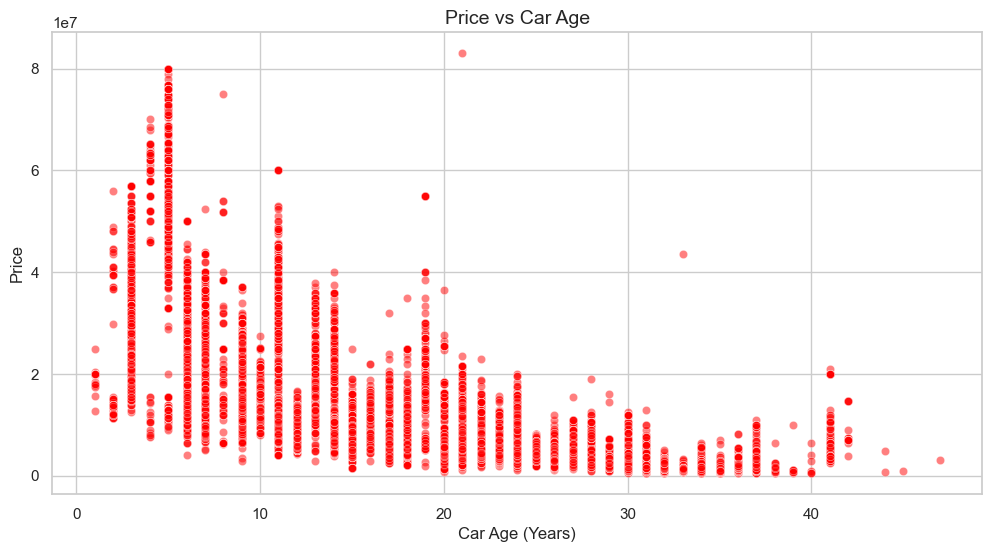

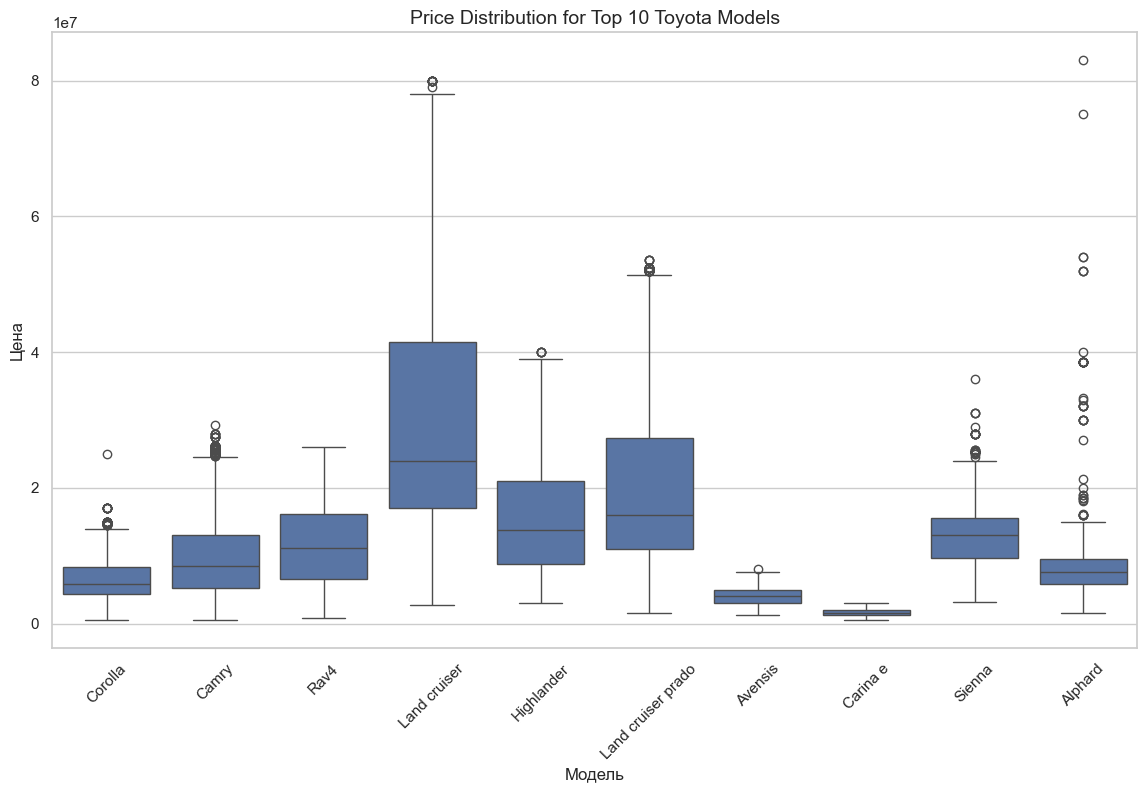

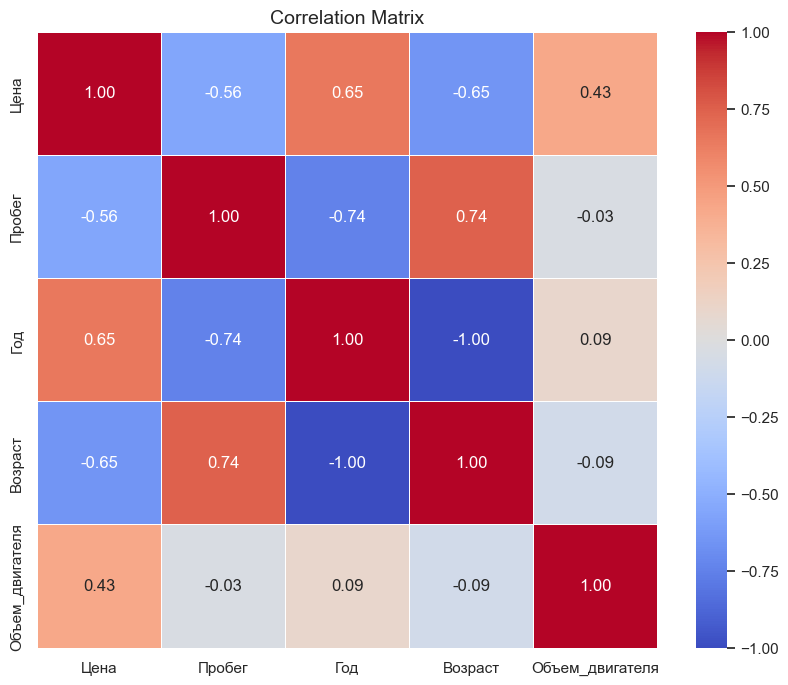

In [87]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("toyota_cleaned_final.csv")

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("--- 1. STATISTICAL SUMMARY ---")
print(df.describe().round(2))
print("\nMissing values count:")
print(df.isnull().sum())

plt.figure(figsize=(12, 6))
sns.histplot(df['Цена'], bins=50, kde=True, color='blue')
plt.title('Distribution of Toyota Car Prices', fontsize=14)
plt.xlabel('Price', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='Возраст', y='Цена', alpha=0.5, color='red')
plt.title('Price vs Car Age', fontsize=14)
plt.xlabel('Car Age (Years)', fontsize=12)
plt.ylabel('Price', fontsize=12)
plt.show()

top_10_models = df['Модель'].value_counts().nlargest(10).index
plt.figure(figsize=(14, 8))
sns.boxplot(data=df[df['Модель'].isin(top_10_models)], x='Модель', y='Цена')
plt.title('Price Distribution for Top 10 Toyota Models', fontsize=14)
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=['int64', 'float64', 'Int64']).columns
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix', fontsize=14)
plt.show()

--- Ridge Regression ---
MAE: 1,972,927 KZT
RMSE: 3,498,786 KZT
MAPE: 17.07%
R2 Score: 0.9021

--- Random Forest ---
MAE: 1,033,631 KZT
RMSE: 1,829,972 KZT
MAPE: 11.37%
R2 Score: 0.9732

--- XGBoost ---
MAE: 1,356,543 KZT
RMSE: 2,239,915 KZT
MAPE: 13.46%
R2 Score: 0.9599



C:\Users\damir\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


--- LightGBM ---
MAE: 1,400,292 KZT
RMSE: 2,340,709 KZT
MAPE: 13.75%
R2 Score: 0.9562

--- CatBoost Regressor ---
MAE: 1,356,363 KZT
RMSE: 2,257,097 KZT
MAPE: 13.54%
R2 Score: 0.9592



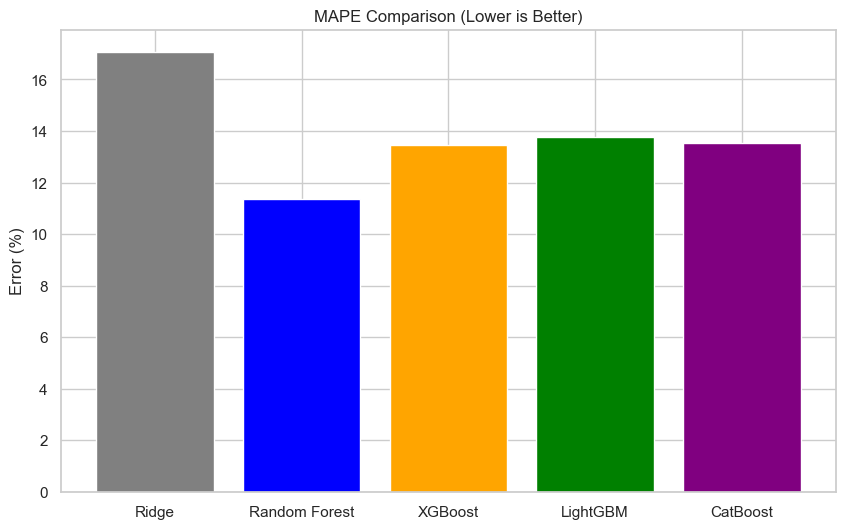

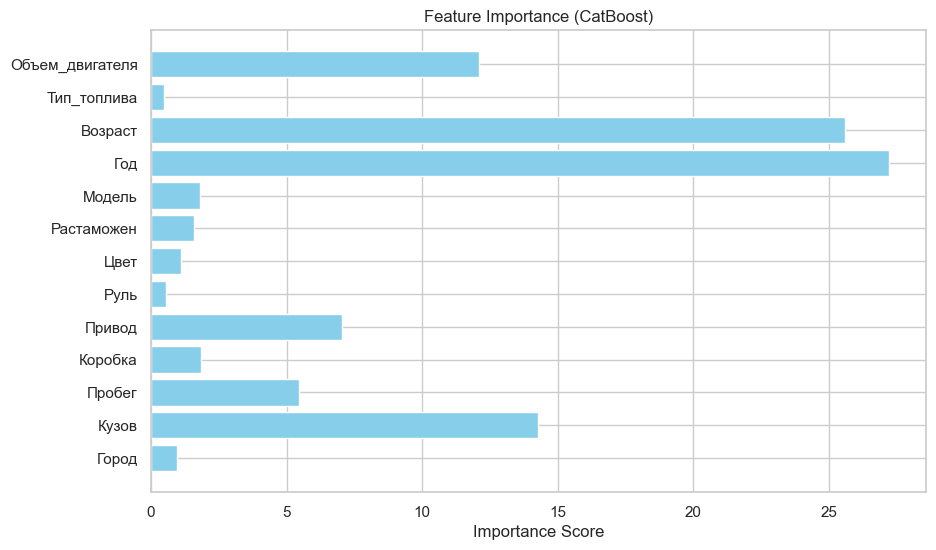

['toyota_model_final.joblib']

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Загрузка данных

df = pd.read_csv("toyota_cleaned_final.csv")
X = df.drop(columns=['Цена', 'Ссылка'], errors='ignore')
y = np.log1p(df['Цена']) 


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Определение признаков

numeric_features = ['Год', 'Возраст', 'Пробег', 'Объем_двигателя']
categorical_features = ['Город', 'Модель', 'Цвет', 'Кузов', 'Коробка', 'Привод', 'Руль', 'Растаможен', 'Тип_топлива']

# 3. Создание трансформеров (Preprocessing)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])



# 4. Функция оценки

def evaluate_model(name, y_true_log, y_pred_log):
    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(y_pred_log)
    
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    
    print(f"--- {name} ---")
    print(f"MAE: {mae:,.0f} KZT")
    print(f"RMSE: {rmse:,.0f} KZT")
    print(f"MAPE: {mape:.2f}%")
    print(f"R2 Score: {r2:.4f}\n")
    return mape

results_mape = {}

# --- Модель 1: Ridge ---

ridge_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                 ('model', Ridge(alpha=1.0))])
ridge_pipeline.fit(X_train, y_train)
y_pred_ridge = ridge_pipeline.predict(X_test)
results_mape["Ridge"] = evaluate_model("Ridge Regression", y_test, y_pred_ridge)

# --- Модель 2: Random Forest ---

rf_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                              ('model', RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42))])
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)
results_mape["Random Forest"] = evaluate_model("Random Forest", y_test, y_pred_rf)

# --- Модель 3: XGBoost ---

xgb_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('model', XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42))])
xgb_pipeline.fit(X_train, y_train)
y_pred_xgb = xgb_pipeline.predict(X_test)
results_mape["XGBoost"] = evaluate_model("XGBoost", y_test, y_pred_xgb)

# --- Модель 4: LightGBM ---

lgb_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('model', LGBMRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42, verbose=-1))])
lgb_pipeline.fit(X_train, y_train)
y_pred_lgb = lgb_pipeline.predict(X_test)
results_mape["LightGBM"] = evaluate_model("LightGBM", y_test, y_pred_lgb)

# --- Модель 5: CatBoost ---

# Для CatBoost заполняем NaN в категориях вручную, так как он работает без пайплайна OneHot

X_train_cat = X_train.copy()
X_test_cat = X_test.copy()
X_train_cat[categorical_features] = X_train_cat[categorical_features].fillna('Missing')
X_test_cat[categorical_features] = X_test_cat[categorical_features].fillna('Missing')

cat_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.1,
    depth=6,
    cat_features=categorical_features,
    verbose=0, 
    random_state=42
)
cat_model.fit(X_train_cat, y_train, eval_set=(X_test_cat, y_test), early_stopping_rounds=20)
y_pred_cat = cat_model.predict(X_test_cat)
results_mape["CatBoost"] = evaluate_model("CatBoost Regressor", y_test, y_pred_cat)

# 5. Визуализация результатов

plt.figure(figsize=(10, 6))
plt.bar(results_mape.keys(), results_mape.values(), color=['gray', 'blue', 'orange', 'green', 'purple'])
plt.title('MAPE Comparison (Lower is Better)')
plt.ylabel('Error (%)')
plt.show()

# 6. Анализ важности признаков для CatBoost

feature_importance = cat_model.get_feature_importance()
plt.figure(figsize=(10, 6))
plt.barh(X.columns, feature_importance, color='skyblue')
plt.title('Feature Importance (CatBoost)')
plt.xlabel('Importance Score')
plt.show()

In [85]:
import joblib
joblib.dump(rf_pipeline, 'toyota_model_final.joblib')

['toyota_model_final.joblib']